# 09 · Anticipación de eventos (próximas 24 h)

**Objetivo:** avisar **antes** de que empiece un evento, no cuando ya se ve. El detector del
notebook 07 enciende la alarma en la primera hora en que un sensor ve el evento; este modelo estima,
cada hora, la probabilidad de que **empiece un evento en la red en las próximas 24 h** y de qué tipo.

En el simulador, la mayoría de los eventos tiene una causa que se ve antes
(`Simulador_sensor/simulador/eventos.py`):

| Tipo | Causa | Qué se puede ver antes |
|---|---|---|
| Turbidez en la fuente | tormenta fuerte (IMN) que satura la planta 2–6 h después | lluvia medida y pronosticada |
| Contaminación | intrusión en un nodo con baja presión, días después de lluvia fuerte | lluvia acumulada, horas de baja presión |
| Falla de cloración | la dosis va cayendo 12–36 h antes de fallar | cloro bajando en la fuente y la red |
| Falla de pH | el pH se va desviando antes de la falla | pH derivando en la fuente |

El resto de los eventos ocurre **al azar** (sin aviso posible): sirven para medir cuántas falsas
esperanzas daría el modelo.

**Cómo se mide:**

| Métrica | Qué significa |
|---|---|
| eventos anticipados | hay un aviso en alguna de las 24 h antes del inicio del evento |
| anticipación | horas entre el primer aviso de esa ventana y el inicio |
| avisos falsos por semana | rachas de horas en aviso sin ningún evento por empezar en las 24 h siguientes |
| con causa | lo mismo, solo con los eventos que tienen una causa que se ve antes (los que se pueden anticipar) |
| AUC-ROC, AUC-PR, F1 por hora | métricas usuales del clasificador, hora por hora |

Las horas con un evento ya en curso (y ninguno por empezar) no se usan: ahí manda el detector.

Se comparan cuatro modelos, cada uno con **un modelo binario por tipo de evento**: **árboles**
(HistGradientBoosting, como el detector), **bosque aleatorio**, **Isolation Forest** (sin etiquetas: aprende la operación normal y marca lo raro) y
**LSTM** (secuencias de 48 h). El umbral y las horas de confirmación de cada uno, y la elección del
modelo, se hacen con **validación por bloques** (como en el notebook 07), sin mirar la prueba.

In [1]:
import sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # por si calidad_agua no está instalado (pip install -e .)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from calidad_agua import anticipacion as A
from calidad_agua import carga, calidad, clima, configuracion, experimentos
from calidad_agua.graficos import estilo, guardar, COLORES, GRIS

estilo()
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

crudo = carga.cargar_todo()
t15 = calidad.lecturas_operativas(crudo)
h = A.horario(t15)
cat = carga.catalogo_eventos()
obj = A.objetivo(h.index, cat)
pron = clima.ventanas(clima.cargar_pronostico(), h.index)
y = obj["clase"].values
utiles = A.filas_utiles(h, obj)

entr = (h["particion"] == "entrenamiento").values
val = (h["particion"] == "validacion").values
prueba = (h["particion"] == "prueba").values
normal_entr = entr & utiles & (y == 0)
T, tipicos = A.tabla(h, pronostico=pron, normal=normal_entr)
X = A.columnas_entrada(T)
PERIODO = {p: tuple(str(f) for f in carga.periodos()[p]) for p in ["validacion", "prueba"]}

NOMBRE = {"contaminacion": "Contaminación", "falla_cloro": "Falla de cloración",
          "turbidez_fuente": "Turbidez en la fuente", "falla_ph": "Falla de pH", "fuga": "Fuga"}
TIPOS = list(NOMBRE)
COLOR = {"contaminacion": COLORES[7], "falla_cloro": COLORES[1], "turbidez_fuente": COLORES[3], "falla_ph": COLORES[6],
         "fuga": COLORES[0]}
def nombre_tipo(k):
    return "anomalía" if k == 0 else carga.TIPOS_EVENTO[k]


CAUSA = {"lluvia": "lluvia", "lluvia_y_baja_presion": "lluvia + baja presión",
         "deterioro_gradual": "deterioro gradual", "aleatoria": "al azar"}
print(f"Tabla: {len(T):,} horas · {len(X)} variables · horas útiles {utiles.mean():.0%}")
print("Eventos por causa:")
print(pd.crosstab(cat["tipo"].map(NOMBRE), cat["causa"].map(CAUSA)).to_string())

reg = experimentos.iniciar("anticipacion_eventos", "09 · anticipación 24 h", "09_anticipacion_eventos")
reg.parametros({"variables_entrada": len(X), "horizonte_h": A.HORIZONTE_H})

Tabla: 17,520 horas · 72 variables · horas útiles 63%
Eventos por causa:
causa                  al azar  deterioro gradual  lluvia  lluvia + baja presión
tipo                                                                            
Contaminación               26                  0       0                     32
Falla de cloración           4                  9       0                      0
Falla de pH                  3                  9       0                      0
Fuga                        25                 31       0                      0
Turbidez en la fuente        1                  0      20                      0


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/09 19:01:04 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. ¿Qué se ve antes de cada tipo de evento?

Promedio de algunas variables alrededor del inicio de cada evento (hora 0), separado por tipo y
según tenga causa o sea al azar. Si una curva cambia **antes** de la hora 0, hay algo que anticipar.

/tmp/ipykernel_5283/2677581605.py:18: RuntimeWarning: Mean of empty slice
  ax[i, j].plot(ventana, np.nanmean(curvas, axis=0), estilo_, color=COLOR[tipo],
/tmp/ipykernel_5283/2677581605.py:18: RuntimeWarning: Mean of empty slice
  ax[i, j].plot(ventana, np.nanmean(curvas, axis=0), estilo_, color=COLOR[tipo],


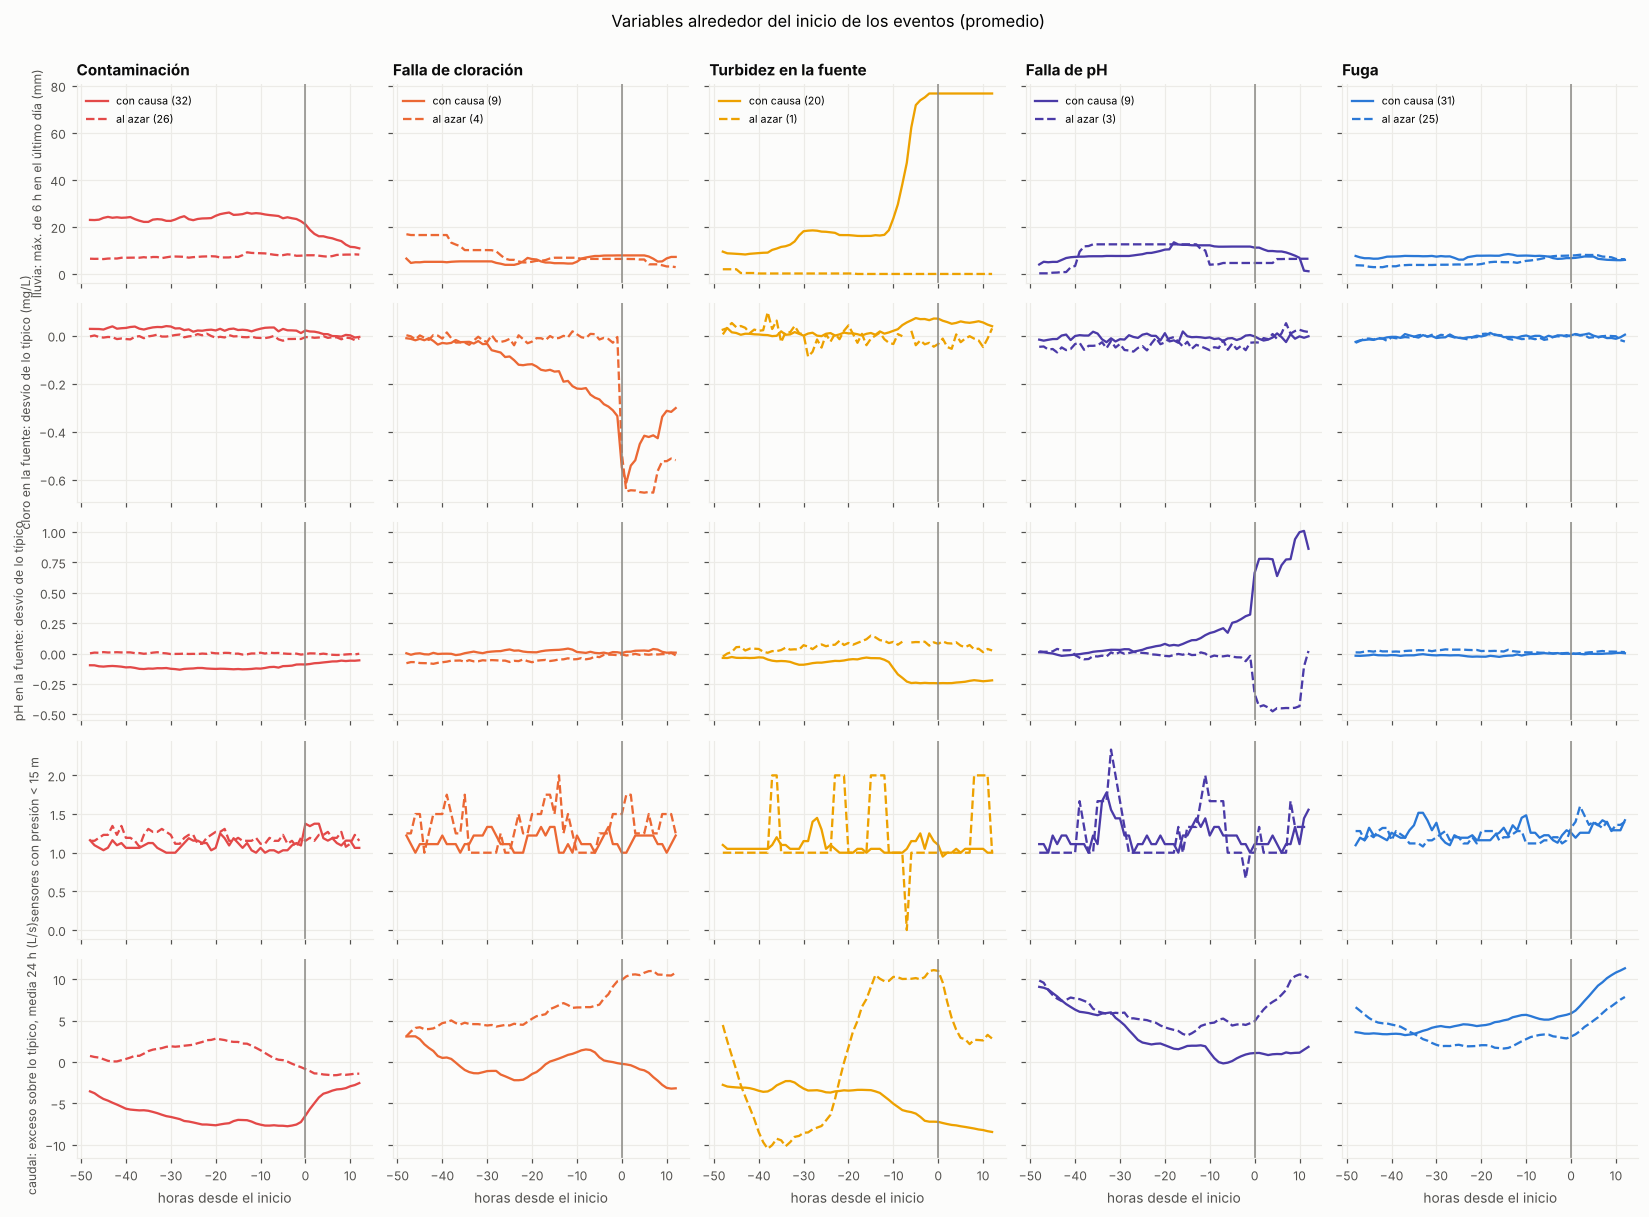

In [2]:
VARS = {"lluvia_6h_max_24h": "lluvia: máx. de 6 h en el último día (mm)",
        "fuente_CL2_desvio": "cloro en la fuente: desvío de lo típico (mg/L)",
        "fuente_PH_desvio": "pH en la fuente: desvío de lo típico",
        "red_sensores_presion_baja": "sensores con presión < 15 m",
        "caudal_desvio_media24h": "caudal: exceso sobre lo típico, media 24 h (L/s)"}
ventana = np.arange(-48, 13)
fig, ax = plt.subplots(len(VARS), len(TIPOS), figsize=(15, 11), sharex=True, sharey="row")
for j, tipo in enumerate(TIPOS):
    for con_causa, estilo_ in [(True, "-"), (False, "--")]:
        sub = cat[(cat["tipo"] == tipo) & ((cat["causa"] != "aleatoria") == con_causa)]
        if sub.empty:
            continue
        for i, (v, etiqueta) in enumerate(VARS.items()):
            curvas = []
            for ini in sub["inicio"].dt.ceil("1h"):
                idx = ini + pd.to_timedelta(ventana, unit="h")
                curvas.append(T[v].reindex(idx).values)
            ax[i, j].plot(ventana, np.nanmean(curvas, axis=0), estilo_, color=COLOR[tipo],
                          label=f"{'con causa' if con_causa else 'al azar'} ({len(sub)})")
    for i, etiqueta in enumerate(VARS.values()):
        ax[i, j].axvline(0, color=GRIS, lw=1)
        ax[i, 0].set_ylabel(etiqueta, fontsize=8)
    ax[0, j].set_title(NOMBRE[tipo], fontsize=10)
    ax[0, j].legend(fontsize=7)
    ax[-1, j].set_xlabel("horas desde el inicio")
fig.suptitle("Variables alrededor del inicio de los eventos (promedio)", y=1.0)
plt.tight_layout()
guardar(fig, "09_antes_de_los_eventos")

## 2. Modelos y validación por bloques

Cada modelo es en realidad **uno por tipo de evento** (¿empieza un evento de este tipo en 24 h?),
salvo el Isolation Forest, que no usa etiquetas y no distingue tipos. Con un solo modelo multiclase,
la contaminación al azar (la clase más numerosa, y la que no tiene aviso posible) se lleva el ajuste
y el modelo no aprende las señales de los otros tipos.

El entrenamiento se parte en cuatro bloques de 4 meses; para cada bloque se entrena con los demás y
se predice ese bloque. Se suma la validación oficial (ene–abr 2026) como quinto bloque, prediciendo
con el modelo entrenado en todo el entrenamiento. Con esas probabilidades **fuera de muestra** se
elige, para cada modelo y cada tipo, el umbral y las horas de confirmación: las que más eventos de
ese tipo anticipan con a lo sumo 2 avisos falsos por semana en total (0,5 por tipo). Un aviso
anticipado es amarillo ("puede venir un evento"): cuesta menos que una falsa alarma del detector,
que tiene tope 1 por semana. Después se elige, entre los modelos que dicen **qué tipo** de evento viene (el
Isolation Forest no lo dice: queda como comparación), el que más eventos **con causa** anticipa
(los eventos al azar no tienen señal previa: anticiparlos sería suerte). La prueba (may–ago 2026)
queda para el final.

In [3]:
BLOQUES = {"sep–dic 2024": ("2024-09-01", "2025-01-01"), "ene–abr 2025": ("2025-01-01", "2025-05-01"),
           "may–ago 2025": ("2025-05-01", "2025-09-01"), "sep–dic 2025": ("2025-09-01", "2026-01-01"),
           "validación (ene–abr 2026)": PERIODO["validacion"]}
LSTM_CFG = A.HIPERPARAMETROS["lstm"]
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")       # sin los mensajes internos de TensorFlow
try:
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")
    CON_LSTM = True
except ImportError:
    CON_LSTM = False
    print("TensorFlow no está instalado: se compara sin la LSTM (pip install -e \"..[red]\")")


def ajustar(nombre, filas):
    # entrena con las filas dadas (útiles); devuelve el modelo y una función que da P (horas × tipo)
    Xe, ye = T.loc[filas, X], y[filas]
    if nombre == "árboles":
        m = A.entrenar_arboles(Xe, ye)
        return m, lambda: A.probabilidades(m, T[X])
    if nombre == "bosque aleatorio":
        m = A.entrenar_bosque(Xe, ye)
        return m, lambda: A.probabilidades(m, T[X])
    if nombre == "Isolation Forest":
        normal = filas & (y == 0)
        m = A.calibrar_isolation(A.entrenar_isolation(T.loc[normal, X]), T.loc[normal, X])
        return m, lambda: A.probabilidades(m, T[X])
    # LSTM: variables estandarizadas con el entrenamiento, secuencias de largo_h horas, una salida por tipo
    media, desv = T.loc[filas, X].mean(), T.loc[filas, X].std().replace(0, 1)
    S = A.secuencias(((T[X] - media) / desv).values, LSTM_CFG["largo_h"])
    Y = np.stack([(ye == k).astype("float32") for k in A.CODIGOS], axis=1)
    peso = np.where(ye > 0, (ye == 0).sum() / max((ye > 0).sum(), 1), 1.0).astype("float32")
    redes = []
    for semilla in LSTM_CFG["semillas"]:
        tf.keras.utils.set_random_seed(semilla)
        red = A.construir_lstm(LSTM_CFG["largo_h"], len(X))
        red.fit(S[filas], Y, sample_weight=peso, epochs=LSTM_CFG["epocas"], batch_size=LSTM_CFG["lote"],
                verbose=0, validation_split=0.1,
                callbacks=[tf.keras.callbacks.EarlyStopping(patience=LSTM_CFG["paciencia"], restore_best_weights=True)])
        redes.append(red)

    def predecir():
        pr = np.mean([r.predict(S, batch_size=2048, verbose=0) for r in redes], axis=0)
        return pd.DataFrame(pr, index=T.index, columns=A.CODIGOS)
    return (redes, media, desv), predecir


MODELOS = ["árboles", "bosque aleatorio", "Isolation Forest"] + (["LSTM"] if CON_LSTM else [])
oof = {}
t0 = time.time()
for nombre_b, (desde, hasta) in BLOQUES.items():
    en_b = (h.index >= desde) & (h.index < hasta)
    filas = entr & utiles & ~en_b
    for m in MODELOS:
        _, predecir = ajustar(m, filas)
        P = predecir()
        oof.setdefault(m, pd.DataFrame(np.nan, index=T.index, columns=P.columns))
        oof[m].loc[en_b] = P.loc[en_b].values
print(f"Validación por bloques: {time.time() - t0:.0f} s")

EL = A.HIPERPARAMETROS["eleccion_aviso"]
en_cv = np.zeros(len(T), bool)
for desde, hasta in BLOQUES.values():
    en_cv |= (h.index >= desde) & (h.index < hasta)


def resumen_modelo(P, eleccion, periodos):
    # aviso combinado (algún tipo) evaluado contra todos los eventos, sumando los periodos
    aviso, tipo = A.avisos_por_tipo(P.fillna(0), eleccion)
    evs, falsos, semanas = [], 0, 0.0
    for desde, hasta in periodos:
        ev, _, r = A.evaluar(h.index, aviso, cat, utiles, desde, hasta, tipo=tipo if 0 not in P else None)
        evs.append(ev); falsos += r["falsos"]; semanas += A._semanas(h.index, utiles, cat, desde, hasta)
    ev = pd.concat(evs)
    en = np.zeros(len(T), bool)
    for desde, hasta in periodos:
        en |= (h.index >= desde) & (h.index < hasta)
    m_ = en & utiles & P.notna().all(axis=1).values
    p_alguno = A.probabilidad_alguno(P.fillna(0))
    mh = A.metricas_hora(y[m_] > 0, p_alguno[m_], 0.5, np.ones(m_.sum(), bool))
    cc = ev[ev["causa"] != "aleatoria"]
    fila = {"eventos": len(ev), "anticipados": int(ev["anticipado"].sum()),
            "% anticipados": 100 * ev["anticipado"].mean(), "anticipación mediana (h)": ev["anticipacion_h"].median(),
            "con causa": len(cc), "con causa anticipados": int(cc["anticipado"].sum()),
            "% con causa anticipados": 100 * cc["anticipado"].mean() if len(cc) else np.nan,
            "anticipación mediana con causa (h)": cc["anticipacion_h"].median(),
            "avisos falsos": falsos, "falsos por semana": falsos / max(semanas, 1e-9),
            "auc_roc (hora)": mh["auc_roc"], "auc_pr (hora)": mh["auc_pr"]}
    for k in [c for c in P.columns if c > 0]:
        mk = m_ & ~np.isnan(P[k].values)
        fila[f"auc_roc {carga.TIPOS_EVENTO[k]}"] = A.metricas_hora(y[mk] == k, P[k].values[mk], 0.5,
                                                                   np.ones(mk.sum(), bool))["auc_roc"]
    return fila, ev, aviso, tipo


eleccion, grillas, filas_cv = {}, [], {}
for m in MODELOS:
    eleccion[m], g = A.elegir_umbrales(h.index, oof[m], cat, utiles, list(BLOQUES.values()),
                                       EL["umbrales"], EL["confirmaciones_h"], EL["max_falsos_por_semana"])
    grillas.append(g.assign(modelo=m))
    filas_cv[m], _, _, _ = resumen_modelo(oof[m], eleccion[m], list(BLOQUES.values()))
grilla = pd.concat(grillas)
cv = pd.DataFrame(filas_cv).T
# el aviso tiene que decir QUÉ evento viene (para saber qué revisar): se elige entre los modelos
# que dan el tipo; el Isolation Forest queda como comparación
con_tipo = cv.drop(index="Isolation Forest", errors="ignore").astype(float)
MEJOR = con_tipo.sort_values(["con causa anticipados", "anticipados", "falsos por semana"],
                             ascending=[False, False, True]).index[0]
print(f"Mejor modelo en la validación por bloques: {MEJOR}")
print("Umbral y confirmación por tipo:", {nombre_tipo(k): v for k, v in eleccion[MEJOR].items()})
reg.tabla(grilla, "grilla_umbral")
reg.tabla(cv.reset_index(names="modelo"), "validacion_por_bloques")
reg.parametros({"modelo_elegido": MEJOR,
                "umbrales": {nombre_tipo(k): u for k, (u, _) in eleccion[MEJOR].items()},
                "confirmacion_h": {nombre_tipo(k): c for k, (_, c) in eleccion[MEJOR].items()}})
cv.astype(float).round(2)

I0000 00:00:1794272466.730907    5283 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794272466.731364    5283 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794272467.536137    5283 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794272467.536445    5283 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Validación por bloques: 247 s


Mejor modelo en la validación por bloques: bosque aleatorio
Umbral y confirmación por tipo: {'contaminacion': (0.6, 1), 'falla_cloro': (0.6, 2), 'turbidez_fuente': (0.5, 2), 'falla_ph': (0.2, 3), 'fuga': (0.5, 3)}


,eventos,anticipados,% anticipados,anticipación mediana (h),con causa,con causa anticipados,% con causa anticipados,anticipación mediana con causa (h),avisos falsos,falsos por semana,auc_roc (hora),auc_pr (hora),auc_roc contaminacion,auc_roc falla_cloro,auc_roc turbidez_fuente,auc_roc falla_ph,auc_roc fuga
árboles,133.0,37.0,27.82,11.0,85.0,30.0,35.29,10.0,41.0,1.14,0.58,0.42,0.61,0.74,0.68,0.70,0.56
bosque aleatorio,133.0,41.0,30.83,11.0,85.0,33.0,38.82,11.0,50.0,1.39,0.60,0.44,0.63,0.75,0.67,0.67,0.56
Isolation Forest,133.0,50.0,37.59,17.0,85.0,42.0,49.41,17.5,66.0,1.83,0.57,0.42,NaN,NaN,NaN,NaN,NaN
LSTM,133.0,30.0,22.56,6.5,85.0,29.0,34.12,6.0,17.0,0.47,0.59,0.43,0.65,0.72,0.64,0.69,0.53


## 3. Evaluación final en el periodo de prueba (may–ago 2026)

Cada modelo se entrena con todo el entrenamiento y se aplica a la prueba con los umbrales y las
confirmaciones que eligió en la validación por bloques.

In [4]:
finales, resultados = {}, {}
for m in MODELOS:
    mod, predecir = ajustar(m, entr & utiles)
    P = predecir()
    fila, ev, aviso, tipo = resumen_modelo(P, eleccion[m], [PERIODO["prueba"]])
    finales[m] = {"modelo": mod, "P": P, "eventos": ev, "aviso": aviso, "tipo": tipo}
    resultados[m] = fila
    with reg.hija(f"09 · {m}") as hija:
        hija.parametros({"modelo": m, **{f"umbral_{nombre_tipo(k)}": u for k, (u, _) in eleccion[m].items()}})
        hija.metricas(fila, "prueba")
        hija.metricas(filas_cv[m], "bloques")
comparacion = pd.DataFrame(resultados).T
reg.tabla(comparacion.reset_index(names="modelo"), "prueba_comparacion")
comparacion.astype(float).round(2)

,eventos,anticipados,% anticipados,anticipación mediana (h),con causa,con causa anticipados,% con causa anticipados,anticipación mediana con causa (h),avisos falsos,falsos por semana,auc_roc (hora),auc_pr (hora),auc_roc contaminacion,auc_roc falla_cloro,auc_roc turbidez_fuente,auc_roc falla_ph,auc_roc fuga
árboles,27.0,10.0,37.04,22.5,16.0,10.0,62.50,22.5,5.0,0.76,0.74,0.68,0.60,1.0,0.73,0.91,0.68
bosque aleatorio,27.0,15.0,55.56,17.0,16.0,12.0,75.00,18.0,12.0,1.82,0.72,0.66,0.64,1.0,0.78,0.95,0.61
Isolation Forest,27.0,11.0,40.74,20.0,16.0,10.0,62.50,22.0,11.0,1.67,0.65,0.51,NaN,NaN,NaN,NaN,NaN
LSTM,27.0,8.0,29.63,10.5,16.0,7.0,43.75,11.0,3.0,0.46,0.67,0.62,0.68,1.0,0.71,0.84,0.64


In [5]:
F = finales[MEJOR]
mod_mejor, P_mejor, ev_p = F["modelo"], F["P"], F["eventos"].copy()
ev_p["causa"] = ev_p["causa"].map(CAUSA)
por_tipo = ev_p.groupby(["tipo", "causa"]).agg(eventos=("anticipado", "size"), anticipados=("anticipado", "sum"),
                                                anticipacion_mediana_h=("anticipacion_h", "median"))
por_tipo["% anticipados"] = 100 * por_tipo["anticipados"] / por_tipo["eventos"]
por_tipo = por_tipo.rename(index=NOMBRE, level=0)
reg.tabla(por_tipo.reset_index(), "prueba_por_tipo_y_causa")
r_p = comparacion.loc[MEJOR]
print(f"{MEJOR} · prueba: {r_p['anticipados']:.0f} de {r_p['eventos']:.0f} eventos anticipados, "
      f"{r_p['falsos por semana']:.2f} avisos falsos por semana")
if MEJOR != "Isolation Forest":
    ok = ev_p[ev_p["anticipado"]]
    print(f"Tipo esperado correcto: {(ok['tipo_sugerido'] == ok['tipo']).sum()} de {len(ok)} anticipados")
con_causa = ev_p[ev_p["causa"] != "al azar"]
print(f"Eventos con causa: {con_causa['anticipado'].sum()} de {len(con_causa)} anticipados · "
      f"al azar: {ev_p.loc[ev_p['causa'] == 'al azar', 'anticipado'].sum()} de {(ev_p['causa'] == 'al azar').sum()}")
por_tipo.round(1)

bosque aleatorio · prueba: 15 de 27 eventos anticipados, 1.82 avisos falsos por semana
Tipo esperado correcto: 9 de 15 anticipados
Eventos con causa: 12 de 16 anticipados · al azar: 3 de 11


eventos  anticipados  anticipacion_mediana_h  % anticipados
tipo                  causa                                                                             
Contaminación         al azar                      7            2                    16.5           28.6
                      lluvia + baja presión        5            4                    20.5           80.0
Falla de cloración    deterioro gradual            2            2                    23.0          100.0
Falla de pH           deterioro gradual            2            2                    17.5          100.0
Fuga                  al azar                      4            1                     9.0           25.0
                      deterioro gradual            4            1                    17.0           25.0
Turbidez en la fuente lluvia                       3            3                    16.0          100.0

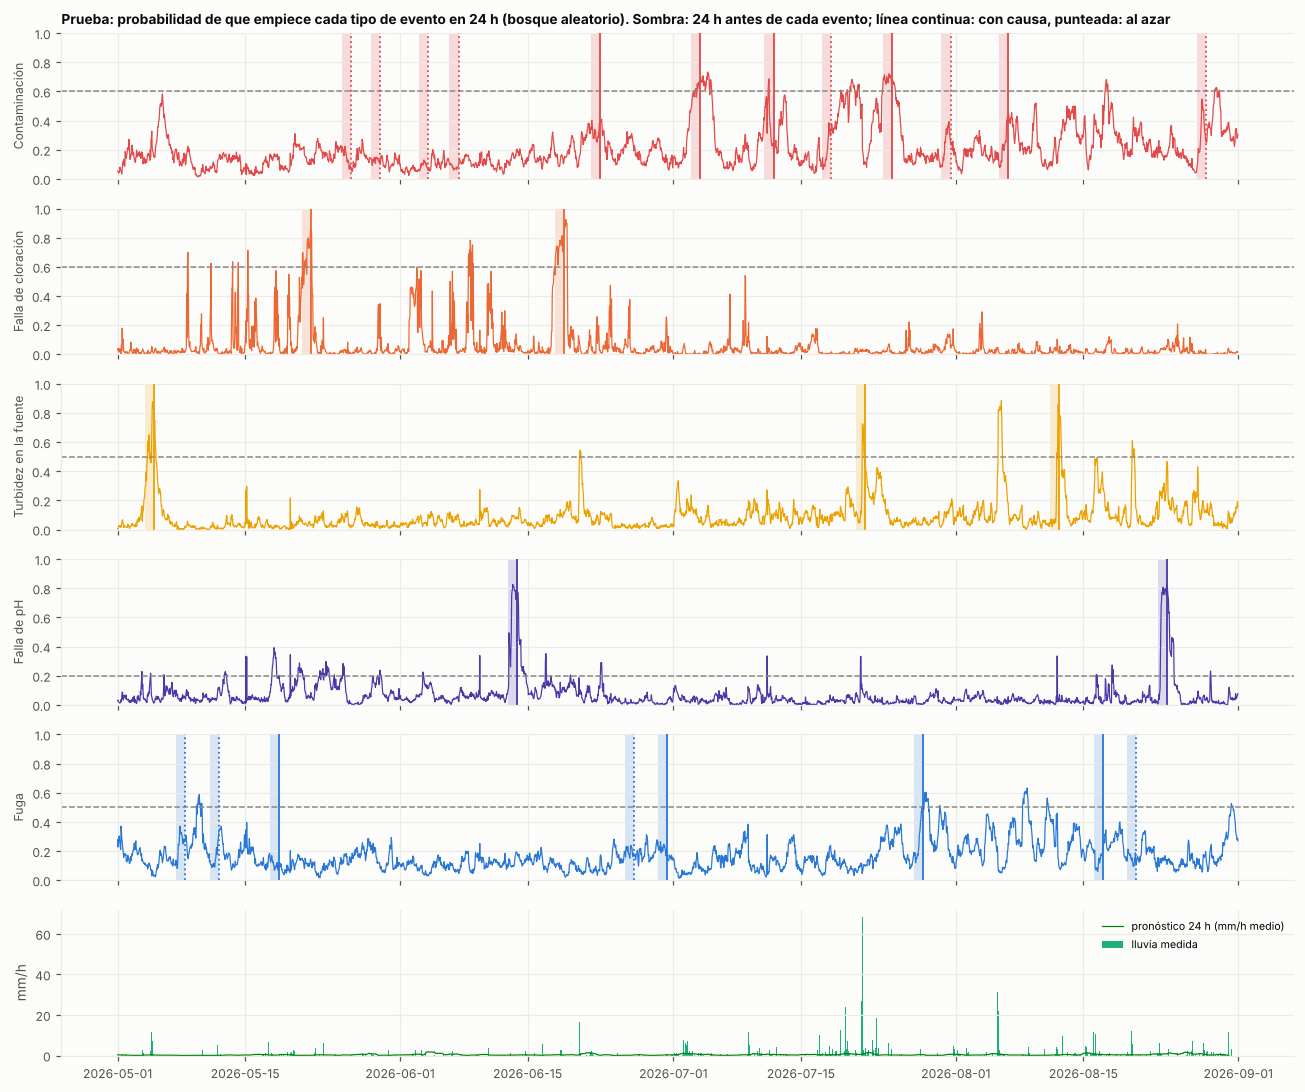

In [6]:
inicio = pd.Timestamp(PERIODO["prueba"][0])
tramo = (h.index >= inicio)
tipos_p = [k for k in P_mejor.columns if k > 0] or [0]
fig, ax = plt.subplots(len(tipos_p) + 1, 1, figsize=(12, 1.6 * len(tipos_p) + 2), sharex=True)
for a, k in zip(ax, tipos_p):
    nombre = carga.TIPOS_EVENTO[k] if k else "contaminacion"
    color = COLOR.get(nombre, COLORES[0])
    a.plot(h.index[tramo], P_mejor[k].values[tramo], color=color, lw=0.8)
    a.axhline(eleccion[MEJOR][k][0], color=GRIS, ls="--", lw=1)
    sub = cat[(cat["inicio"] >= inicio) & ((cat["codigo"] == k) | (k == 0))]
    for _, e in sub.iterrows():
        a.axvspan(e["inicio"] - pd.Timedelta(hours=24), e["inicio"], color=color, alpha=0.18, lw=0)
        a.axvline(e["inicio"], color=color, lw=1.2, ls="-" if e["causa"] != "aleatoria" else ":")
    a.set_ylabel(NOMBRE.get(nombre, "anomalía") if k else "anomalía", fontsize=8)
    a.set_ylim(0, 1)
ax[-1].bar(h.index[tramo], T["lluvia_1h"].values[tramo], width=1 / 24, color=COLORES[2], label="lluvia medida")
ax[-1].plot(h.index[tramo], T["lluvia_pron_24h"].values[tramo] / 24, color=COLORES[5], lw=0.8,
            label="pronóstico 24 h (mm/h medio)")
ax[-1].set_ylabel("mm/h"); ax[-1].legend(fontsize=7)
ax[0].set_title(f"Prueba: probabilidad de que empiece cada tipo de evento en 24 h ({MEJOR}). "
                "Sombra: 24 h antes de cada evento; línea continua: con causa, punteada: al azar", fontsize=9)
plt.tight_layout()
guardar(fig, "09_linea_tiempo_prueba")

## 3b. Horizonte de 48 h

El informe pide avisos con **24 a 48 horas** de antelación. Con el mismo tipo de modelo elegido,
otra versión aprende "¿empieza un evento en las próximas **48 h**?", con su propia validación por
bloques para el umbral y la confirmación de cada tipo, y se evalúa una vez en la prueba. Un aviso a
48 h acierta si el evento empieza dentro de las 48 h siguientes; es falso si no empieza ninguno.

In [7]:
H48 = 48
obj48 = A.objetivo(h.index, cat, horizonte=H48)
y48 = obj48["clase"].values
utiles48 = A.filas_utiles(h, obj48)
mod48 = eleccion48 = None
# a 48 h se usa el modelo de árboles elegido o, si se eligió la LSTM o el Isolation Forest, el mejor
# de los dos de árboles en la validación por bloques (más rápido de entrenar y de explicar)
MODELO48 = MEJOR if MEJOR in ("árboles", "bosque aleatorio") else \
    con_tipo.loc[["árboles", "bosque aleatorio"]].sort_values(
        ["con causa anticipados", "anticipados", "falsos por semana"], ascending=[False, False, True]).index[0]
print(f"Modelo a 48 h: {MODELO48}")


def ajustar48(filas):
    entrenar = A.entrenar_bosque if MODELO48 == "bosque aleatorio" else A.entrenar_arboles
    return entrenar(T.loc[filas, X], y48[filas])


if True:
    oof48 = pd.DataFrame(np.nan, index=T.index, columns=A.CODIGOS)
    for desde, hasta in BLOQUES.values():
        en_b = (h.index >= desde) & (h.index < hasta)
        P_b = A.probabilidades(ajustar48(entr & utiles48 & ~en_b), T[X])
        oof48.loc[en_b] = P_b.loc[en_b, A.CODIGOS].values
    eleccion48, _ = A.elegir_umbrales(h.index, oof48, cat, utiles48, list(BLOQUES.values()), EL["umbrales"],
                                      EL["confirmaciones_h"], EL["max_falsos_por_semana"], horizonte=H48)
    mod48 = ajustar48(entr & utiles48)
    P48 = A.probabilidades(mod48, T[X])
    filas48 = {}
    for nombre_h, (Pm, el, ut, hz) in {"24 h": (finales[MODELO48]["P"], eleccion[MODELO48], utiles, A.HORIZONTE_H),
                                       "48 h": (P48, eleccion48, utiles48, H48)}.items():
        aviso_h, tipo_h = A.avisos_por_tipo(Pm.fillna(0), el)
        ev_h, _, r_h = A.evaluar(h.index, aviso_h, cat, ut, *PERIODO["prueba"], horizonte=hz, tipo=tipo_h)
        cc = ev_h[ev_h["causa"] != "aleatoria"]
        filas48[nombre_h] = {"eventos": len(ev_h), "anticipados": int(ev_h["anticipado"].sum()),
                             "con causa": len(cc), "con causa anticipados": int(cc["anticipado"].sum()),
                             "anticipación mediana (h)": ev_h["anticipacion_h"].median(),
                             "avisos falsos": r_h["falsos"],
                             "falsos por semana": r_h["falsos"] / A._semanas(h.index, ut, cat, *PERIODO["prueba"], hz)}
        if nombre_h == "48 h":
            ev48 = ev_h
    horizontes = pd.DataFrame(filas48).T
    horizontes.index = [f"{x} ({MODELO48})" for x in horizontes.index]
    print("Umbral y confirmación por tipo (48 h):", {nombre_tipo(k): v for k, v in eleccion48.items()})
    reg.tabla(horizontes.reset_index(names="horizonte"), "prueba_24_y_48h")
    reg.metricas(filas48["48 h"], "prueba_48h")
    display(horizontes.astype(float).round(2))
    display(ev48.assign(causa=ev48["causa"].map(CAUSA)).groupby(["tipo", "causa"])
            .agg(eventos=("anticipado", "size"), anticipados=("anticipado", "sum"),
                 anticipacion_mediana_h=("anticipacion_h", "median")).rename(index=NOMBRE, level=0))

Modelo a 48 h: bosque aleatorio


Umbral y confirmación por tipo (48 h): {'contaminacion': (0.7, 3), 'falla_cloro': (0.5, 3), 'turbidez_fuente': (0.6, 1), 'falla_ph': (0.5, 2), 'fuga': (0.7, 1)}


,eventos,anticipados,con causa,con causa anticipados,anticipación mediana (h),avisos falsos,falsos por semana
24 h (bosque aleatorio),27.0,15.0,16.0,12.0,17.0,12.0,1.82
48 h (bosque aleatorio),27.0,14.0,16.0,12.0,25.5,3.0,0.83


eventos  anticipados  anticipacion_mediana_h
tipo                  causa                                                              
Contaminación         al azar                      7            2                     9.5
                      lluvia + baja presión        5            5                    40.0
Falla de cloración    deterioro gradual            2            2                    20.0
Falla de pH           deterioro gradual            2            2                    14.0
Fuga                  al azar                      4            0                     NaN
                      deterioro gradual            4            0                     NaN
Turbidez en la fuente lluvia                       3            3                    31.0

## 4. Variables más importantes del modelo elegido

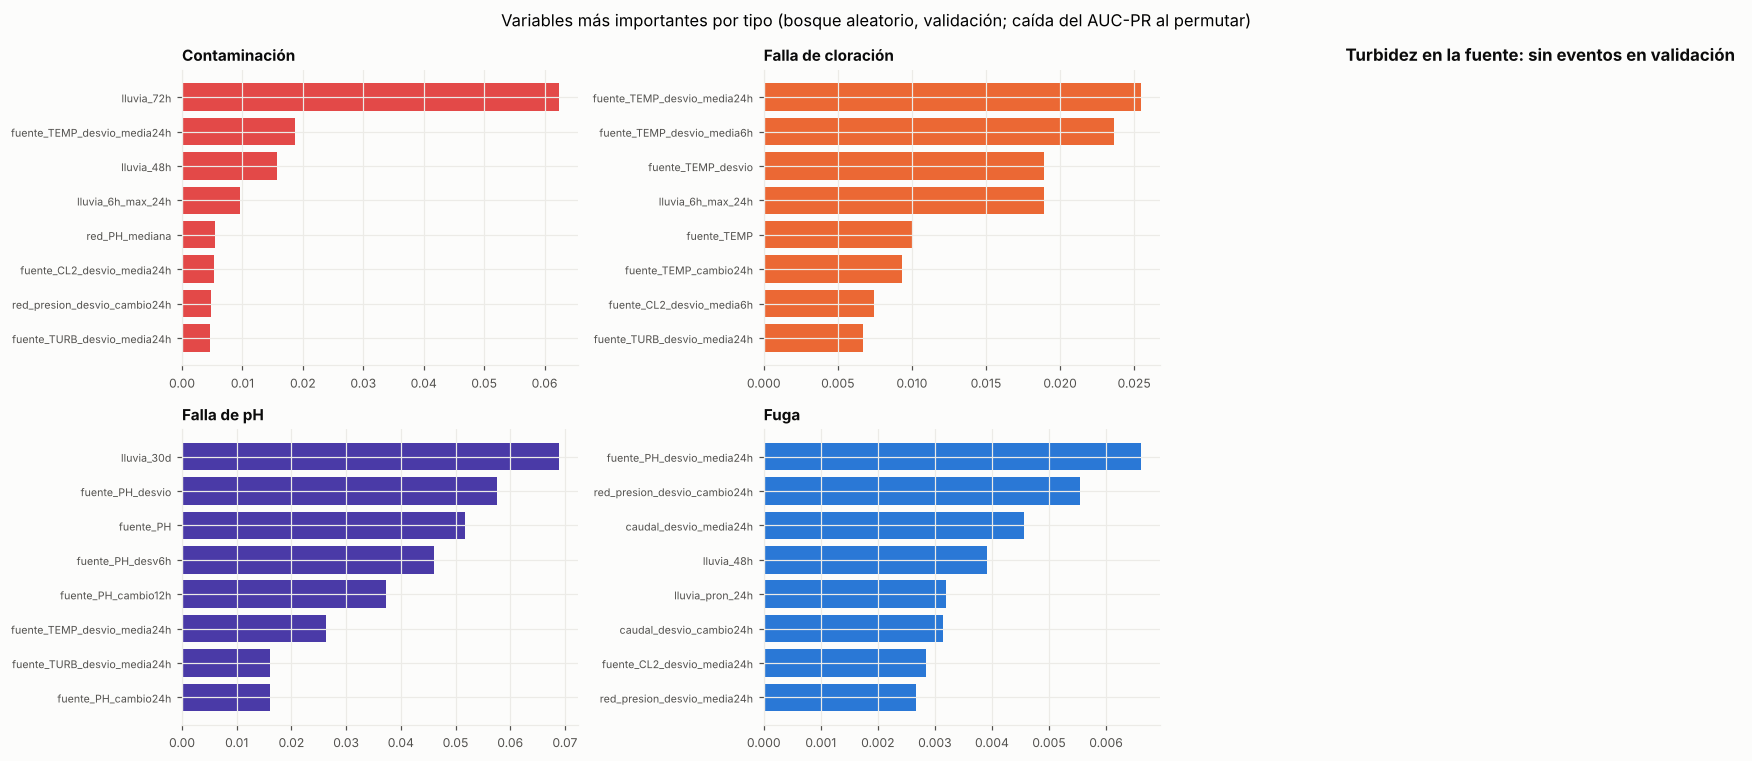

In [8]:
from sklearn.inspection import permutation_importance
if MEJOR in ("árboles", "bosque aleatorio"):
    filas_i = val & utiles
    fig, ax = plt.subplots(2, 3, figsize=(16, 7))
    for a, k in zip(ax.ravel(), A.CODIGOS):
        m_k = mod_mejor[k]
        yk = (y[filas_i] == k).astype(int)
        if m_k is None or yk.sum() == 0:
            a.set_axis_off(); a.set_title(f"{NOMBRE[carga.TIPOS_EVENTO[k]]}: sin eventos en validación"); continue
        Xi = T.loc[filas_i, X] if MEJOR == "árboles" else T.loc[filas_i, X].fillna(-999)
        r_imp = permutation_importance(m_k, Xi, yk, n_repeats=3, random_state=0, scoring="average_precision")
        imp = pd.Series(r_imp.importances_mean, index=X).sort_values(ascending=False).head(8)
        a.barh(imp.index[::-1], imp.values[::-1], color=COLOR[carga.TIPOS_EVENTO[k]])
        a.set_title(NOMBRE[carga.TIPOS_EVENTO[k]], fontsize=10)
        a.tick_params(axis="y", labelsize=7)
    for a in ax.ravel()[len(A.CODIGOS):]:
        a.set_axis_off()
    fig.suptitle(f"Variables más importantes por tipo ({MEJOR}, validación; caída del AUC-PR al permutar)")
    plt.tight_layout()
    guardar(fig, "09_importancia_variables")
else:
    print("El modelo elegido no es de árboles: se omite la importancia por permutación.")

## 5. ¿Cuándo llega a cada sensor un evento de la fuente?

Las fallas de cloración y de pH y la turbidez empiezan en la planta y viajan por la red. Con los
eventos del entrenamiento se mide cuántas horas pasan desde que se ven en la salida de la fuente
(J280) hasta que se ven en cada sensor. En operación, cuando se anticipa o se detecta un evento de
la fuente, esto da la hora estimada de llegada a cada sensor.

sensor,J280,J439,J224,J69,J1058,J237,J345,J101,J284,J144
mediana,0.0,1.0,2.0,2.0,2.0,2.0,3.0,3.0,3.0,15.5
minimo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
maximo,0.0,1.0,5.0,3.0,3.0,3.0,8.0,3.0,6.0,18.0
eventos,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,35.0,34.0


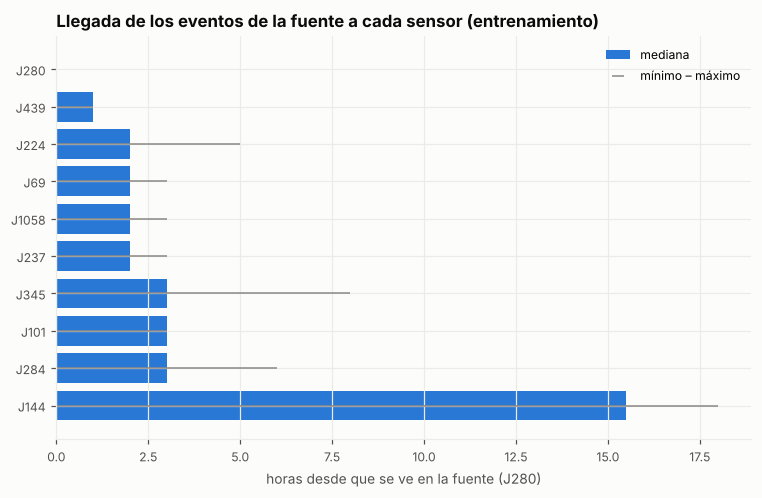

In [9]:
E_h = crudo[[c for c in crudo.columns if c.startswith("evento_") and c[7:] in carga.sensores(crudo)]].resample("1h").max()
cat_entr = cat[cat["inicio"] < pd.Timestamp(PERIODO["validacion"][0])]
retrasos = A.retrasos_propagacion(E_h, cat_entr, carga.sensores(crudo))
reg.tabla(retrasos.reset_index(), "retrasos_propagacion")
orden = retrasos.sort_values("mediana")
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(orden.index[::-1], orden["mediana"][::-1], color=COLORES[0], label="mediana")
ax.errorbar(orden["mediana"][::-1], orden.index[::-1],
            xerr=[(orden["mediana"] - orden["minimo"])[::-1], (orden["maximo"] - orden["mediana"])[::-1]],
            fmt="none", ecolor=GRIS, lw=1, label="mínimo – máximo")
ax.set_xlabel("horas desde que se ve en la fuente (J280)")
ax.set_title("Llegada de los eventos de la fuente a cada sensor (entrenamiento)")
ax.legend()
plt.tight_layout()
guardar(fig, "09_propagacion")
orden.round(1).T

## 6. Guardar el modelo

In [10]:
carpeta = Path.cwd().parent / "modelos"
carpeta.mkdir(exist_ok=True)
paquete = {"nombre": MEJOR, "columnas": X, "tipicos": tipicos, "eleccion": eleccion[MEJOR],
           "horizonte_h": A.HORIZONTE_H, "retrasos_propagacion": retrasos, "mlflow": reg.referencia()}
if MEJOR == "LSTM":
    redes, media, desv = mod_mejor
    for k, red in enumerate(redes):
        red.save(carpeta / f"anticipacion_lstm_{k}.keras")
    paquete.update({"media": media, "desv": desv, "largo_h": LSTM_CFG["largo_h"], "redes": len(redes)})
else:
    paquete["modelo"] = mod_mejor
if mod48 is not None:                       # aviso a 48 h (sección 3b)
    paquete.update({"modelo_48h": mod48, "nombre_48h": MODELO48, "eleccion_48h": eleccion48, "horizonte_48h": H48})
joblib.dump(paquete, carpeta / "anticipacion_24h.joblib", compress=3)
print("Guardado: modelos/anticipacion_24h.joblib",
      f"({(carpeta / 'anticipacion_24h.joblib').stat().st_size / 1e6:.1f} MB)")
reg.archivo(carpeta / "anticipacion_24h.joblib")
reg.metricas(comparacion.loc[MEJOR].to_dict(), "prueba")
reg.figuras_guardadas("09_")
reg.terminar()
print(f"Registrado en MLflow: experimento anticipacion_eventos, corrida {reg.id}")

Guardado: modelos/anticipacion_24h.joblib (26.0 MB)
Registrado en MLflow: experimento anticipacion_eventos, corrida 487f3109131e4327bc519593e0668eed


## 7. Conclusiones

**Resultado en el periodo de prueba (may–ago 2026)**, con los 10 sensores del sistema, el bosque
aleatorio (elegido en la validación por bloques) y un umbral por tipo:

| | Resultado |
|---|---|
| Eventos **con causa** anticipados | **12 de 16 (75 %)**, con 18 h de anticipación mediana |
| Falla de cloración con deterioro previo | 2 de 2 (23 h antes) |
| Falla de pH con deterioro previo | 2 de 2 (17 h antes) |
| Turbidez en la fuente por tormenta | 3 de 3 (16 h antes) |
| Contaminación por lluvia y baja presión | 4 de 5 (20 h antes) |
| Fuga que empieza pequeña | 1 de 4 |
| Eventos al azar anticipados | 3 de 11 (no tienen señal previa) |
| Tipo esperado correcto | 9 de los 15 avisos que acertaron |
| Avisos falsos | **1,8 por semana** (1,4 en la validación por bloques) |

**A 48 h** (sección 3b, también con el bosque aleatorio): **12 de 16 eventos con causa (75 %)**,
con 25 h de anticipación mediana y solo 0,8 avisos falsos por semana; las 5 contaminaciones por
lluvia y baja presión se anticipan (40 h antes), pero ninguna fuga. Con más horizonte el aviso
tiene más tiempo para encenderse antes del evento y, con umbrales más altos, da menos avisos
falsos.

En la validación por bloques (20 meses, 85 eventos con causa) el bosque aleatorio anticipa **33 de
85 (39 %)** con 1,4 avisos falsos por semana; los árboles, 30 (1,1); la LSTM, 29 (0,5), y el
Isolation Forest, 42 (1,8, sin decir el tipo).

**Lo que muestra el modelo**

1. **Lo que tiene causa se puede anticipar, y cada tipo con su propia señal** (sección 1):
   - **Falla de cloración:** el cloro de la fuente baja poco a poco desde unas 30 h antes. Es el
     tipo que mejor se anticipa (AUC 1,0 por hora en la prueba; 0,75 en los bloques).
   - **Falla de pH:** la deriva previa del pH de la fuente (AUC 0,84 a 0,95 en la prueba).
   - **Turbidez en la fuente:** la tormenta se ve en la lluvia medida 3 a 8 h antes; el pronóstico
     de lluvia casi no anuncia los aguaceros fuertes (notebook 04).
   - **Contaminación:** la señal es débil (AUC 0,6–0,7): lluvia de los últimos días y horas de baja
     presión.
   - **Fuga que crece:** el exceso de caudal sobre lo típico en 24 h sube antes de la rotura, pero
     es pequeño frente a la variación normal del consumo (AUC 0,6–0,7): casi no se anticipa.
2. **Un modelo por tipo fue la clave.** Con un solo modelo para todos los tipos, las contaminaciones
   al azar (la clase más numerosa y la que no se puede anticipar) se llevaban el ajuste.
3. **Con 10 sensores la elección cambió de la LSTM al bosque aleatorio,** que anticipa más pero
   avisa en falso más seguido. En la prueba, el bosque anticipa 12 de 16 eventos con causa con 1,8
   avisos falsos por semana; la LSTM, 7 de 16 con 0,5; con 3 sensores la LSTM elegida anticipaba 8
   de 16 con 0,5. En los bloques los cuatro modelos quedan cerca (29 a 33 de 85 con causa, sin
   contar el Isolation Forest), así que lo que decide es cuántos avisos falsos acepta la ASADA: si
   prefiere menos, la LSTM o el modelo a 48 h. El Isolation Forest no dice qué tipo de evento
   viene, así que no sirve para decidir qué revisar.
4. **El tipo que anuncia el aviso es casi siempre el correcto** (9 de 15 en la prueba): el operador
   sabe si revisar la dosificación, la planta o buscar una intrusión.
5. **Los eventos de la fuente llegan a cada sensor con un retraso que se conoce** (sección 5): 1 h
   en mediana a J439, 2 h a J224, J237, J69 y J1058, 3 h a J345, J101 y J284, y 15 h al extremo de la
   red (J144). Cuando se anticipa o se detecta un evento en la planta, el aviso dice en cuántas
   horas llegará a cada punto.

**Precauciones**

- **Pocos eventos en la prueba.** Son 16 con causa en cuatro meses; un evento más o menos mueve
  varios puntos el porcentaje. El resultado más estable es el de la validación por bloques, y ahí
  10 sensores anticipan lo mismo que 3 (39 % contra 40 % de los eventos con causa): las señales
  de la anticipación son de la fuente, la lluvia y el caudal, que no cambian con más sensores.
- **1,8 avisos falsos por semana es mucho para un operador.** Conviene revisarlo con la ASADA: el
  umbral de cada tipo está en `hiperparametros.yaml` y la regla de elección se puede ajustar para
  aceptar menos avisos falsos.
- **Las causas son las del simulador.** Que el modelo las aprenda muestra que el método funciona
  cuando los eventos tienen una causa medible; en la red real habrá que confirmar cuáles se dan y
  con qué señales.

**Qué queda en el servicio**

`modelos/anticipacion_24h.joblib` (bosque aleatorio, un modelo por tipo, con su umbral y
confirmación, los retrasos de propagación y el modelo a 48 h). El servicio lo usa para mandar un
**aviso anticipado** (amarillo) con el tipo esperado, la probabilidad, la señal que lo explica y la
llegada estimada a cada sensor. El detector (notebook 07) y el modelo de fugas (notebook 10) se
encargan de la alarma (roja) cuando el evento ya se ve.
